# Zero-shot classification with SigLIP 2 and CLIP

A robot that meets a new object category should not need a new labelled dataset and a
new training run. **Vision-language dual encoders** such as CLIP and SigLIP map images and
text into one embedding space, so a classifier for *any* list of class names can be built
by encoding the names as sentences. No training is involved.

This notebook evaluates two such models on the 3,925 validation images of **Imagenette-160**
(a 10-class ImageNet subset). It then runs them on frames from a real robot-workspace sequence
(TUM RGB-D `fr1_desk`), where none of the 10 classes appears:

| model | checkpoint | training loss | score at test time |
|---|---|---|---|
| **SigLIP 2** B/16, 224 px | `google/siglip2-base-patch16-224` (transformers) | pairwise **sigmoid** | independent probability per (image, text) pair |
| **CLIP** B/32, 224 px | open_clip `ViT-B-32` / `laion2b_s34b_b79k` | batch **softmax** (InfoNCE) | distribution over the given classes |

**What you'll learn**
- how a zero-shot classifier is built from text embeddings, and why prompt templates and prompt ensembling matter;
- the difference between CLIP's softmax and SigLIP's sigmoid scores, and why the sigmoid suits open-world robotics (it can say "none of these" and tag several objects at once);
- a silent preprocessing pitfall in SigLIP 2 (text padding);
- how to measure accuracy, confusion, throughput and peak VRAM honestly.

**Prerequisites:** basic PyTorch, cosine similarity, softmax. Run `make data-13_vision_language`
first (Imagenette-160, TUM `fr1_desk` and the checkpoints). The notebook runs in about 1 minute on an
RTX 5060 Laptop GPU (8 GB).

## Setup

`cvlab.device.setup()` seeds every RNG, selects the GPU and prints the software versions, so
every number below can be traced to the stack that produced it. The model wrappers live in
`projects/13_vision_language/scripts/vl_common.py`; the checkpoint revisions are pinned in
`configs/models.yaml`.

In [1]:
# --- Setup: imports, device, repo-relative paths, plotting style ---
# vl_common.py (in this project's scripts/ folder) wraps the model loading and the
# small pure functions (prompt ensembling, answer parsing, ...) that are unit-tested.
import os
import sys

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")  # keep notebook outputs clean

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import transformers
from IPython.display import display

import cvlab.device
from cvlab import viz
from cvlab.io import data_dir, project_dir

transformers.logging.set_verbosity_error()  # silence config/loader chatter
transformers.utils.logging.disable_progress_bar()

PROJECT = "13_vision_language"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import vl_common as vl  # noqa: E402

device = cvlab.device.setup(seed=0)  # seeds RNGs, picks the GPU, prints versions
viz.set_style()
RESULTS = project_dir(PROJECT) / "results"
RESULTS.mkdir(exist_ok=True)
TUM_RGB = data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk", "rgb")
print("transformers", transformers.__version__, "| results ->", vl.rel(RESULTS))

import time

import torch
from open_clip import zero_shot_metadata as zsm
from sklearn.metrics import roc_auc_score

from cvlab.bench import benchmark
from cvlab.metrics import confusion_matrix

IMAGENETTE = data_dir("imagenette", "imagenette2-160")
print("data:", vl.rel(IMAGENETTE), "|", vl.rel(TUM_RGB))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
transformers 5.22.2 | results -> projects/13_vision_language/results


data: data/imagenette/imagenette2-160 | data/tum/fr1_desk/rgbd_dataset_freiburg1_desk/rgb


## 1. The data: Imagenette-160 validation split

Imagenette is a 10-class subset of ImageNet whose classes are easy to tell apart. The
"160" version stores images with a shorter side of 160 px. Both models resize them to 224 px,
so they see slightly upsampled, blurry inputs. Class names are the cleaned ImageNet names
that OpenAI released with CLIP (for example `n03417042` becomes "garbage truck").

3925 validation images, 10 classes
images per class: {'tench': 387, 'English Springer Spaniel': 395, 'cassette player': 357, 'chainsaw': 386, 'church': 409, 'French horn': 394, 'garbage truck': 389, 'gas pump': 419, 'golf ball': 399, 'parachute': 390}


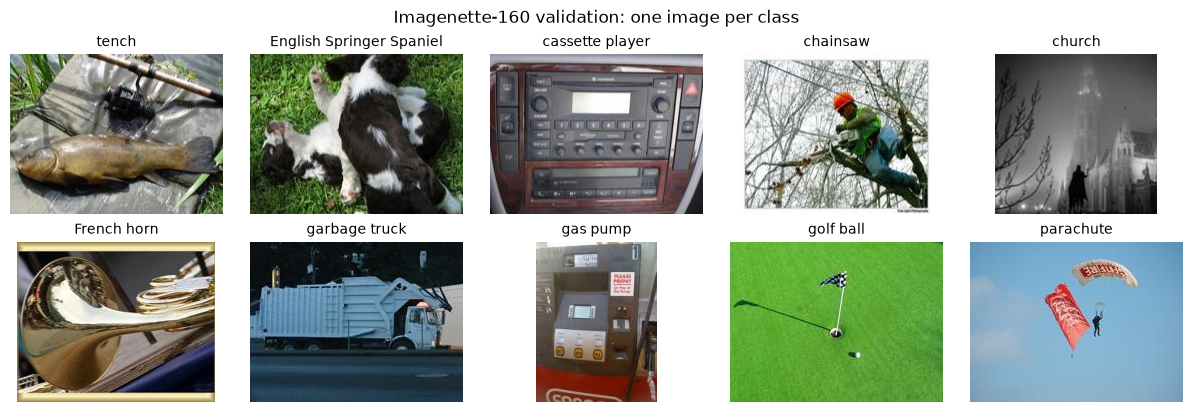

In [2]:
# --- Load the validation split and show one example per class ---
# imagenette_split returns sorted file paths and integer labels (index into `classes`).
paths, labels = vl.imagenette_split(IMAGENETTE, "val")
classes = list(vl.IMAGENETTE_CLASSES.values())
print(f"{len(paths)} validation images, {len(classes)} classes")
print("images per class:", dict(zip(classes, np.bincount(labels).tolist())))

first = [int(np.flatnonzero(labels == k)[0]) for k in range(len(classes))]
fig = viz.show_images([np.asarray(vl.load_rgb(paths[i])) for i in first], classes, ncols=5, size=2.4,
                      suptitle="Imagenette-160 validation: one image per class")
plt.show()

## 2. Theory: contrastive dual encoders

An image encoder $f$ and a text encoder $g$ produce L2-normalised embeddings
$\mathbf{x}_i = f(I_i)/\lVert f(I_i)\rVert$ and $\mathbf{y}_j = g(T_j)/\lVert g(T_j)\rVert$. Both models
are trained on billions of web image-alt-text pairs so that matching pairs have a high
cosine similarity $\mathbf{x}_i^\top \mathbf{y}_j$. They differ in the loss:

**CLIP (softmax / InfoNCE).** For a batch of $N$ pairs with a learned temperature $t$, each
image must pick its own caption out of the $N$ captions (and vice versa):

$$\mathcal{L}_\text{CLIP} = -\frac{1}{2N}\sum_{i=1}^{N}\left[\log\frac{e^{t\,\mathbf{x}_i^\top\mathbf{y}_i}}{\sum_{j} e^{t\,\mathbf{x}_i^\top\mathbf{y}_j}} + \log\frac{e^{t\,\mathbf{x}_i^\top\mathbf{y}_i}}{\sum_{j} e^{t\,\mathbf{x}_j^\top\mathbf{y}_i}}\right]$$

**SigLIP (sigmoid).** Every (image, text) pair is an independent binary problem, "do these
two match?", with a learned temperature $t$ and bias $b$. Here $z_{ij}=1$ for matching pairs
and $-1$ otherwise:

$$\mathcal{L}_\text{SigLIP} = -\frac{1}{N}\sum_{i=1}^{N}\sum_{j=1}^{N} \log \sigma\!\left(z_{ij}\,(t\,\mathbf{x}_i^\top\mathbf{y}_j + b)\right)$$

There is no normalisation across the batch. This makes the loss cheaper to scale and, more
importantly for us, the score $\sigma(t\,\mathbf{x}^\top\mathbf{y} + b)$ is a calibrated-looking
**per-pair probability**. SigLIP 2 keeps this loss and adds captioning, self-distillation and
masked-prediction objectives that improve dense features and localisation.

**Zero-shot classification.** Write each class $c$ as one or more prompts ("a photo of a
{class}."), embed them, average the unit vectors and renormalise. This is *prompt
ensembling*, and it gives the class weight $\mathbf{w}_c$. Then

$$\hat{c} = \arg\max_c\, \mathbf{x}^\top \mathbf{w}_c, \qquad
p_\text{CLIP}(c\mid I) = \operatorname{softmax}_c(t\,\mathbf{x}^\top\mathbf{w}_c), \qquad
p_\text{SigLIP}(c\mid I) = \sigma(t\,\mathbf{x}^\top\mathbf{w}_c + b).$$

The argmax, and therefore the accuracy, is the same for both score functions. They differ in
what the numbers *mean*: softmax scores always sum to 1 over the classes you happened to list,
while sigmoid scores do not have to.

## 3. Load both models and embed every validation image

Both encoders run in fp16. `vram_meter` records the peak CUDA memory of each block
relative to what was already allocated, so the second model's number does not include the
first model's weights. We time the full pass over the 3,925 images, including JPEG decoding and
preprocessing on the CPU (end-to-end throughput). Model-only throughput is measured later.

In [3]:
# --- Load SigLIP 2 and CLIP, embed all validation images (fp16) and record cost ---
# encode_images returns (N, D) float32 unit vectors as NumPy arrays (D = 768 / 512).
encoders, img_emb, cost = {}, {}, {}
for Enc in (vl.SigLIP2Encoder, vl.OpenCLIPEncoder):
    with vl.vram_meter() as mem:
        enc = Enc(device)
        t0 = time.perf_counter()
        img_emb[enc.name] = enc.encode_images(paths, batch_size=64)
        sec = time.perf_counter() - t0
    encoders[enc.name] = enc
    cost[enc.name] = {"params (M)": vl.n_params(enc.model), "embed dim": img_emb[enc.name].shape[1],
                      "end-to-end img/s": len(paths) / sec, "peak VRAM (MiB)": mem.delta_mb}
    print(f"{enc.name:20s} {vl.n_params(enc.model):6.1f} M params | {len(paths)} images in {sec:5.1f} s "
          f"({len(paths) / sec:5.0f} img/s) | peak VRAM +{mem.delta_mb:.0f} MiB | "
          f"temperature t = {enc.scale:.1f}, bias b = {enc.bias:.2f}")
siglip, clip = encoders.values()

SigLIP 2 B/16-224     375.2 M params | 3925 images in 119.2 s (   33 img/s) | peak VRAM +980 MiB | temperature t = 112.5, bias b = -16.77


CLIP B/32 (LAION-2B)  151.3 M params | 3925 images in  98.3 s (   40 img/s) | peak VRAM +371 MiB | temperature t = 100.0, bias b = 0.00


SigLIP 2 learned a strongly negative bias $b$. With $t \approx 112$ and $b \approx -17$, a pair
needs a cosine similarity above $-b/t \approx 0.15$ before its probability passes 0.5. Most
image-text pairs on the web do *not* match, so the model learned a low prior.

## 4. Prompt engineering and prompt ensembling

The text encoder never saw bare class names during training. It saw alt-text sentences. We
compare five ways of turning a class name into a classifier weight:

* the bare class name, `"{}"`;
* CLIP's default single template, `"a photo of a {}."`;
* SigLIP 2's documented template, `"This is a photo of {}."`;
* the 7 templates that the CLIP authors selected for ImageNet;
* the full set of 80 ImageNet templates ("a bad photo of a {}.", "a sculpture of a {}.", ...), averaged.

Text embeddings are cheap (10 classes x 80 templates = 800 sentences), so every variant
costs about a second.

In [4]:
# --- Accuracy of every (model, prompt variant) pair on the 3,925 validation images ---
# build_prompts is class-major; ensemble_text_embeddings averages each class's unit vectors.
TEMPLATES = {
    "class name only": ["{}"],
    "a photo of a {}.": ["a photo of a {}."],
    "This is a photo of {}.": ["This is a photo of {}."],
    "7-template ensemble": [t("{}") for t in zsm.SIMPLE_IMAGENET_TEMPLATES],
    "80-template ensemble": [t("{}") for t in zsm.OPENAI_IMAGENET_TEMPLATES],
}
class_emb, rows = {}, []
for name, enc in encoders.items():
    for variant, tpl in TEMPLATES.items():
        w = vl.ensemble_text_embeddings(enc.encode_texts(vl.build_prompts(classes, tpl)), len(classes))
        class_emb[name, variant] = w
        pred = (img_emb[name] @ w.T).argmax(1)  # cosine similarity -> argmax (same for both scores)
        rows.append({"model": name, "prompt": variant, "n templates": len(tpl),
                     "top-1 acc": float((pred == labels).mean())})
acc = pd.DataFrame(rows)
display(acc.pivot(index="prompt", columns="model", values="top-1 acc").loc[list(TEMPLATES)]
        .style.format("{:.2%}"))

model,CLIP B/32 (LAION-2B),SigLIP 2 B/16-224
prompt,,
class name only,99.11%,97.55%
a photo of a {}.,99.01%,98.17%
This is a photo of {}.,98.75%,93.96%
7-template ensemble,99.03%,98.32%
80-template ensemble,99.06%,97.78%


### A silent pitfall: SigLIP 2 text padding

SigLIP's text tower was trained on captions padded to exactly 64 tokens, and it pools the
sequence without an attention mask. If you call the processor with the usual
`padding=True` / `"longest"`, the sequences get shorter and the pooled embedding changes. Nothing
errors and nothing warns. Let's measure what it costs.

In [5]:
# --- SigLIP 2 with the wrong text padding (padding="longest" instead of "max_length", 64) ---
# Same template, same images: only the tokenizer padding differs.
tpl = ["This is a photo of {}."]
for pad in ("max_length", "longest"):
    w = siglip.encode_texts(vl.build_prompts(classes, tpl), padding=pad)
    p = vl.zero_shot_scores(img_emb[siglip.name], w, siglip.scale, siglip.bias, "sigmoid")
    print(f"padding={pad:10s}: top-1 {np.mean(p.argmax(1) == labels):.2%} | "
          f"mean max-probability {p.max(1).mean():.3f}")

padding=max_length: top-1 93.96% | mean max-probability 0.365
padding=longest   : top-1 10.19% | mean max-probability 0.000


## 5. Where do the errors go? Confusion matrices

We use each model's best prompt variant from the table above. A confusion matrix
$C_{ij}$ counts the images of true class $i$ predicted as $j$. Off-diagonal mass shows which
categories the text prompts fail to separate.

In [6]:
# --- Confusion matrices and per-class accuracy for each model's best prompt variant ---
best = acc.loc[acc.groupby("model")["top-1 acc"].idxmax()].set_index("model")
preds, cms = {}, {}
for name in encoders:
    w = class_emb[name, best.loc[name, "prompt"]]
    preds[name] = (img_emb[name] @ w.T).argmax(1)
    cms[name] = confusion_matrix(labels, preds[name], len(classes))
per_class = pd.DataFrame({name: np.diag(cm) / cm.sum(1) for name, cm in cms.items()}, index=classes)
display(per_class.style.format("{:.1%}").background_gradient(cmap="RdYlGn", vmin=0.8, vmax=1.0))

,SigLIP 2 B/16-224,CLIP B/32 (LAION-2B)
tench,99.2%,99.7%
English Springer Spaniel,91.9%,99.7%
cassette player,99.2%,98.0%
chainsaw,97.7%,97.9%
church,100.0%,99.8%
French horn,98.0%,99.0%
garbage truck,99.5%,99.0%
gas pump,99.3%,99.0%
golf ball,100.0%,99.0%
parachute,98.5%,99.7%


## 6. Softmax vs sigmoid when the answer is "none of these"

A robot's camera mostly sees things that are *not* in its label list. We embed 31 frames
of the TUM `fr1_desk` sequence (every 20th frame: monitors, keyboards, books, a telephone),
classify them into the 10 Imagenette classes, and compare the **maximum score** with the one on
real Imagenette images:

* CLIP's softmax must distribute probability 1 over the 10 classes, so even a desk gets a confident "label".
* SigLIP's sigmoid scores each class independently, so all 10 can be low at once.

The AUROC measures how well the maximum score separates in-distribution images (positives)
from desk frames (negatives). 1.0 is perfect separation and 0.5 is chance.

In [7]:
# --- Max score on in-distribution images vs out-of-distribution robot-desk frames ---
# zero_shot_scores: softmax for CLIP, sigmoid(t*cos + b) for SigLIP (scale/bias are learned).
desk_files = sorted(TUM_RGB.glob("*.png"))[::20]
desk_imgs = [vl.load_rgb(p) for p in desk_files]
max_scores, ood_rows = {}, []
for name, enc in encoders.items():
    w = class_emb[name, best.loc[name, "prompt"]]
    p_in = vl.zero_shot_scores(img_emb[name], w, enc.scale, enc.bias, enc.kind).max(1)
    p_out = vl.zero_shot_scores(enc.encode_images(desk_imgs), w, enc.scale, enc.bias, enc.kind).max(1)
    max_scores[name] = (p_in, p_out)
    auroc = roc_auc_score(np.r_[np.ones(len(p_in)), np.zeros(len(p_out))], np.r_[p_in, p_out])
    ood_rows.append({"model": name, "score": enc.kind, "median max score (Imagenette)": np.median(p_in),
                     "median max score (desk frames)": np.median(p_out), "AUROC in vs out": auroc})
ood = pd.DataFrame(ood_rows).set_index("model")
display(ood.style.format("{:.3f}", subset=list(ood.columns[1:])))

,score,median max score (Imagenette),median max score (desk frames),AUROC in vs out
model,,,,
SigLIP 2 B/16-224,sigmoid,0.091,0.003,0.806
CLIP B/32 (LAION-2B),softmax,1.000,0.880,0.968


## 7. Open-vocabulary multi-label tagging of a robot workspace

The same property makes SigLIP a usable **multi-label tagger**. We write a vocabulary of
desk objects plus a few distractors that are absent from the scene (cat, banana, car) and read
off $\sigma(t\,\mathbf{x}^\top\mathbf{w}_c + b)$ for every frame and word. CLIP's softmax over the
same vocabulary is shown for contrast: a frame showing a monitor *and* a keyboard has to split
its probability mass between them.

In [8]:
# --- Per-frame scores for a desk vocabulary: SigLIP sigmoid vs CLIP softmax ---
VOCAB = ["computer monitor", "computer keyboard", "computer mouse", "laptop", "telephone",
         "game controller", "book", "coffee mug", "office chair", "cat", "banana", "car"]
tag_scores = {}
for name, enc in encoders.items():
    tpl = ["This is a photo of {}."] if enc.kind == "sigmoid" else ["a photo of a {}."]
    w = enc.encode_texts(vl.build_prompts(VOCAB, tpl))
    tag_scores[name] = vl.zero_shot_scores(enc.encode_images(desk_imgs), w, enc.scale, enc.bias, enc.kind)
sig = tag_scores[siglip.name]
present = pd.Series((sig > 0.5).mean(0), index=VOCAB, name="fraction of frames with p > 0.5")
display(present.to_frame().T.style.format("{:.0%}"))

,computer monitor,computer keyboard,computer mouse,laptop,telephone,game controller,book,coffee mug,office chair,cat,banana,car
fraction of frames with p > 0.5,3%,0%,3%,0%,0%,6%,0%,0%,0%,0%,0%,0%


## 8. Throughput and memory

End-to-end throughput (Section 3) is limited by JPEG decoding and resizing on the CPU. To see
the model itself, we time the image encoder alone on a pre-processed batch of 64 images with
`cvlab.bench.benchmark`, which calls `torch.cuda.synchronize()` around every iteration.

In [9]:
# --- Model-only image-encoder throughput at batch 64 (fp16, CUDA-synchronised timing) ---
batch = [vl.load_rgb(p) for p in paths[:64]]
for name, enc in encoders.items():
    px = enc.preprocess(batch)  # (64, 3, 224, 224) fp16 on the GPU
    with torch.inference_mode(), vl.vram_meter() as mem:
        t = benchmark(enc._img, px, warmup=5, iters=20)
    cost[name] |= {"model-only img/s (bs 64)": 64 * t["fps"], "latency bs 64 (ms)": t["mean_ms"],
                   "activations bs 64 (MiB)": mem.delta_mb}
    print(f"{name:20s} {t['mean_ms']:6.1f} ms / batch of 64 -> {64 * t['fps']:6.0f} img/s")

SigLIP 2 B/16-224     167.4 ms / batch of 64 ->    382 img/s


CLIP B/32 (LAION-2B)   34.2 ms / batch of 64 ->   1873 img/s


## Results

All numbers come from the cells above (RTX 5060 Laptop GPU, 8 GB, fp16). First, accuracy
for every prompt variant, plus each model's confusion matrix for its best variant.

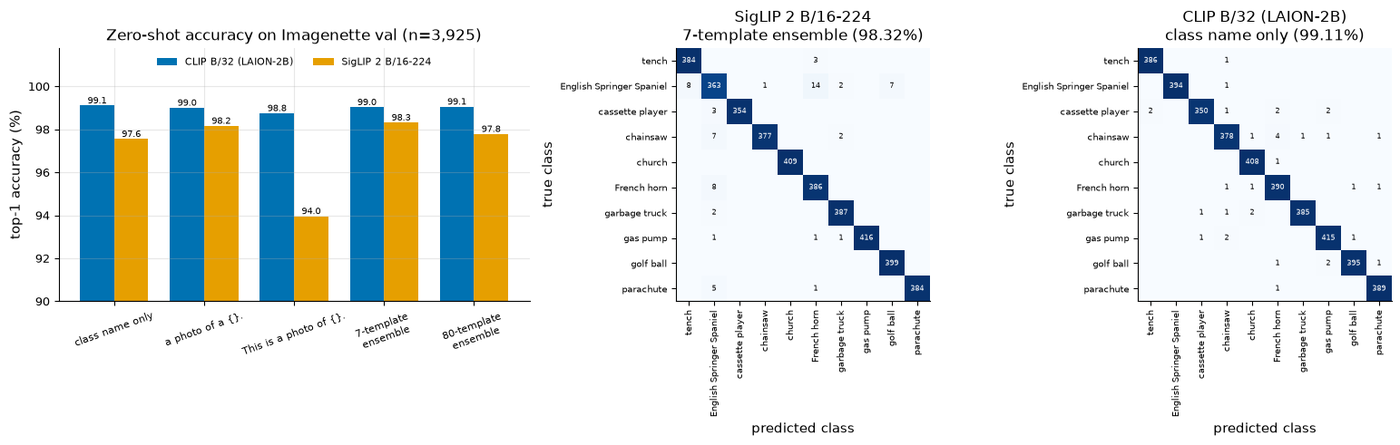

In [10]:
# --- Figure: accuracy by prompt variant + confusion matrices (saved for the README) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.25, 1, 1]})
piv = acc.pivot(index="prompt", columns="model", values="top-1 acc").loc[list(TEMPLATES)]
x = np.arange(len(piv))
for k, name in enumerate(piv.columns):
    bars = axes[0].bar(x + (k - 0.5) * 0.38, 100 * piv[name], 0.38, label=name, color=viz.color(k, unit=True))
    axes[0].bar_label(bars, fmt="%.1f", fontsize=7)
axes[0].set_xticks(x, [s.replace(" ensemble", "\nensemble") for s in piv.index], rotation=20, fontsize=8)
axes[0].set_ylim(90, 101.8)
axes[0].set(ylabel="top-1 accuracy (%)", title="Zero-shot accuracy on Imagenette val (n=3,925)")
axes[0].legend(loc="upper center", ncol=2, frameon=False, fontsize=8)
for ax, (name, cm) in zip(axes[1:], cms.items()):
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i, j in zip(*np.nonzero(cm)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6, color="w" if i == j else "k")
    ax.set_xticks(range(len(classes)), classes, rotation=90, fontsize=7)
    ax.set_yticks(range(len(classes)), classes, fontsize=7)
    ax.grid(False)
    ax.set(xlabel="predicted class", ylabel="true class",
           title=f"{name}\n{best.loc[name, 'prompt']} ({best.loc[name, 'top-1 acc']:.2%})")
viz.savefig(fig, PROJECT, "zero_shot_accuracy")
plt.show()

Next, the open-world behaviour: the distribution of the maximum class score on Imagenette
images and on robot-desk frames, and the multi-label desk-vocabulary scores.

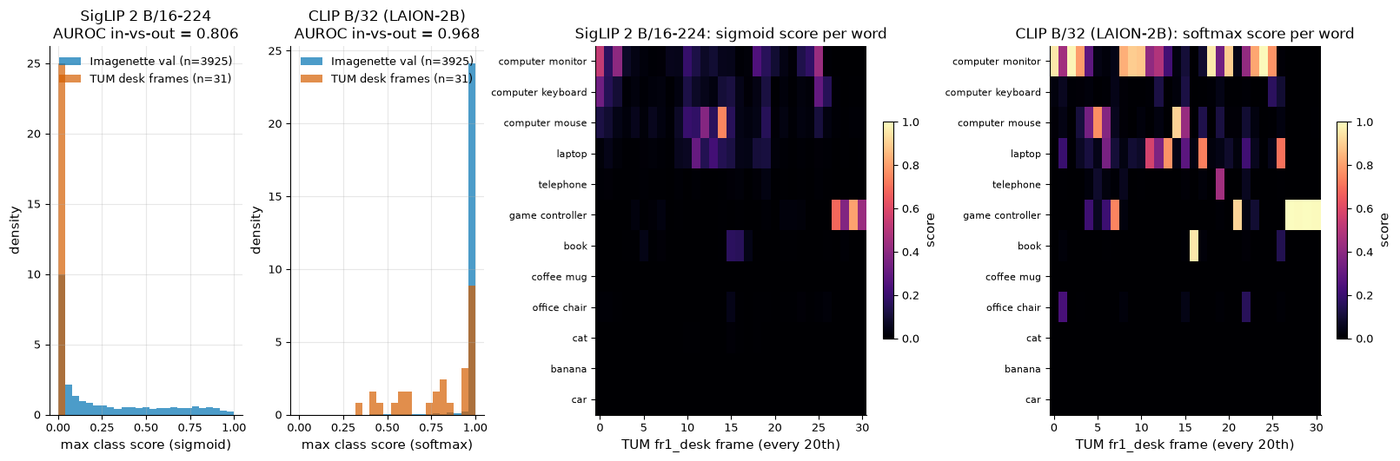

In [11]:
# --- Figure: max-score distributions (in vs out of distribution) + desk tagging heatmaps ---
fig = plt.figure(figsize=(16, 5.2))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1.4, 1.4])
for k, (name, (p_in, p_out)) in enumerate(max_scores.items()):
    ax = fig.add_subplot(gs[0, k])
    bins = np.linspace(0, 1, 26)
    ax.hist(p_in, bins, density=True, alpha=0.7, label=f"Imagenette val (n={len(p_in)})", color=viz.color(0, unit=True))
    ax.hist(p_out, bins, density=True, alpha=0.7, label=f"TUM desk frames (n={len(p_out)})", color=viz.color(5, unit=True))
    ax.set(xlabel=f"max class score ({encoders[name].kind})", ylabel="density",
           title=f"{name}\nAUROC in-vs-out = {ood.loc[name, 'AUROC in vs out']:.3f}")
    ax.legend(loc="upper center")
for k, name in enumerate(tag_scores):
    ax = fig.add_subplot(gs[0, 2 + k])
    im = ax.imshow(tag_scores[name].T, aspect="auto", cmap="magma", vmin=0, vmax=1)
    ax.set_yticks(range(len(VOCAB)), VOCAB, fontsize=8)
    ax.set(xlabel="TUM fr1_desk frame (every 20th)", title=f"{name}: {encoders[name].kind} score per word")
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.04, label="score")
viz.savefig(fig, PROJECT, "open_world_scores")
plt.show()

A gallery of SigLIP 2 mistakes shows what the errors look like. The tiny 160 px inputs and
ambiguous scenes (a church *and* a parachute in the sky, a person holding a fish) account for most of them.

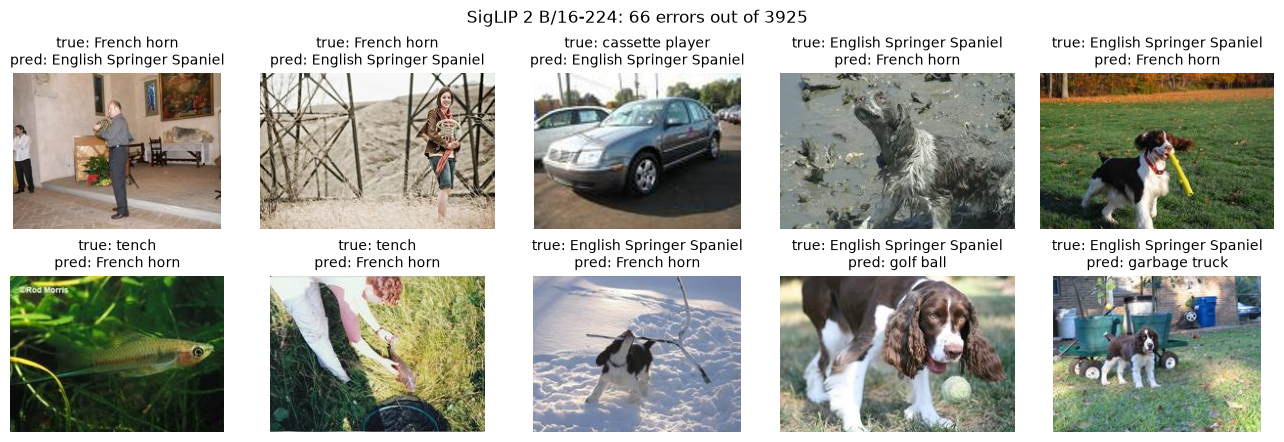

In [12]:
# --- Figure: misclassified validation images (SigLIP 2, best prompt) ---
wrong = np.flatnonzero(preds[siglip.name] != labels)
pick = np.random.default_rng(0).choice(wrong, size=min(10, len(wrong)), replace=False)
fig = viz.show_images([np.asarray(vl.load_rgb(paths[i])) for i in pick],
                      [f"true: {classes[labels[i]]}\npred: {classes[preds[siglip.name][i]]}" for i in pick],
                      ncols=5, size=2.6, suptitle=f"{siglip.name}: {len(wrong)} errors out of {len(paths)}")
viz.savefig(fig, PROJECT, "zero_shot_failures")
plt.show()

### Summary table

One row per model: the best accuracy, the effect of prompt ensembling, the open-set
separation and the measured cost. The table is also written to `results/zero_shot_summary.csv`.

In [13]:
# --- Summary table of the measured numbers (also saved as CSV for the README) ---
piv = acc.pivot(index="model", columns="prompt", values="top-1 acc")
summary = pd.DataFrame({
    "best prompt": best["prompt"],
    "top-1 (best prompt)": best["top-1 acc"],
    "top-1 (class name only)": piv["class name only"],
    "top-1 (80-template ensemble)": piv["80-template ensemble"],
    "AUROC Imagenette vs desk": ood["AUROC in vs out"],
}).join(pd.DataFrame(cost).T)
summary.to_csv(RESULTS / "zero_shot_summary.csv", float_format="%.4f")
display(summary.style.format({c: "{:.2%}" for c in summary.columns if c.startswith("top-1")} | {
    "AUROC Imagenette vs desk": "{:.3f}", "params (M)": "{:.1f}", "embed dim": "{:.0f}", "end-to-end img/s": "{:.0f}",
    "peak VRAM (MiB)": "{:.0f}", "model-only img/s (bs 64)": "{:.0f}", "latency bs 64 (ms)": "{:.1f}",
    "activations bs 64 (MiB)": "{:.0f}"}))

,best prompt,top-1 (best prompt),top-1 (class name only),top-1 (80-template ensemble),AUROC Imagenette vs desk,params (M),embed dim,end-to-end img/s,peak VRAM (MiB),model-only img/s (bs 64),latency bs 64 (ms),activations bs 64 (MiB)
model,,,,,,,,,,,,
CLIP B/32 (LAION-2B),class name only,99.11%,99.11%,99.06%,0.968,151.3,512,40,371,1873,34.2,56
SigLIP 2 B/16-224,7-template ensemble,98.32%,97.55%,97.78%,0.806,375.2,768,33,980,382,167.4,220


### Takeaways

* **Zero-shot works on Imagenette without any training.** CLIP B/32 reaches 99.11% top-1 with
  the bare class name and SigLIP 2 B/16 reaches 98.32% with the 7-template ensemble, on all 3,925
  validation images.
* **The prompt matters as much as the model.** SigLIP 2 ranges from 93.96% ("This is a photo of
  {}.", the template from its model card) to 98.32% (7-template ensemble). Ensembling gains
  +0.77 points over the bare class name for SigLIP 2 and nothing for CLIP (99.11% vs 99.03% / 99.06%).
  Always measure your templates on your own data.
* **Pre-processing is part of the model.** Tokenising SigLIP 2 prompts with `padding="longest"`
  instead of `padding="max_length", max_length=64` drops accuracy from 93.96% to 10.19% (chance)
  without any error message.
* **Softmax vs sigmoid, honestly.** The textbook argument says sigmoid scores should make "none of
  these" easier. On our test the opposite happened: the max-softmax score of CLIP separates
  Imagenette from desk frames with AUROC 0.968, SigLIP 2's max-sigmoid only 0.806. SigLIP 2's
  absolute probabilities are low even for correct in-distribution images (median max score
  0.091 on blurry 160 px inputs), and on the desk frames a monitor gets $p > 0.5$ in only 3% of
  frames. The sigmoid scores still rank and tag independently (no mass split between "monitor"
  and "keyboard"), but a robot needs per-word thresholds tuned on its own camera.
* **Cost.** SigLIP 2 B/16 has 2.5x the parameters of CLIP B/32 (375 M vs 151 M) and its image
  encoder is 4.9x slower at batch 64 (382 vs
  1,873 img/s model-only, fp16); peak VRAM is 980 vs 371 MiB. End-to-end throughput
  (33 vs 40 img/s here) is limited by JPEG decoding on the CPU and changes from
  run to run when other jobs share the CPU; the model-only numbers are the stable ones.

## Exercises

Solutions are in `projects/13_vision_language/solutions/ex01_zero_shot.py` (run it with
`python projects/13_vision_language/solutions/ex01_zero_shot.py`).

**Exercise 1: class-name engineering.** Prompt templates only wrap the class name. The name
itself matters more: "tench" is a rare word. Rewrite the names of each model's two weakest classes
(see the per-class table) with a short description, for example `"tench, a type of freshwater fish"`,
then measure the change in their per-class accuracy and in the overall accuracy.

In [14]:
# --- Exercise 1: descriptive class names for the weakest classes ---
# TODO: copy `classes`, replace the weakest names with descriptions, rebuild the class weights
# with the model's best template(s) and compare per-class and overall accuracy.

**Exercise 2: few-shot linear probe vs zero-shot.** Embed the Imagenette *train* split and fit a
logistic-regression classifier (scikit-learn) on $k \in \{1, 2, 4, 8, 16\}$ images per class. At
which $k$ does a few-shot probe overtake the zero-shot classifier? Average over 3 random draws of
the shots.

In [15]:
# --- Exercise 2: k-shot logistic regression on frozen image embeddings ---
# TODO: embed vl.imagenette_split(IMAGENETTE, "train"), sample k shots per class,
# fit sklearn.linear_model.LogisticRegression and evaluate on img_emb (validation).

**Exercise 3: an "unknown object" threshold.** Choose, for each model, the threshold on the max
score that keeps 95% of the Imagenette validation images (5% false rejections). What fraction of
the 613 `fr1_desk` frames does it reject as "none of the known classes"? Which score function would
you deploy on a robot?

In [16]:
# --- Exercise 3: open-set rejection with a max-score threshold ---
# TODO: threshold = np.quantile(p_in, 0.05); embed every fr1_desk frame and report
# the fraction with max score < threshold, for SigLIP 2 (sigmoid) and CLIP (softmax).